# SPVM FIGURES
This notebook contains the figures I will be using in my poster in spvm


# n(t) vs t 
Figure 2 in the second paper

In [ ]:
# 1. Define the 3-parameter function
def logistic_model(t, N_0, k, t_0):
    return N_0 / (1 + np.exp(-k * (t - t_0)))




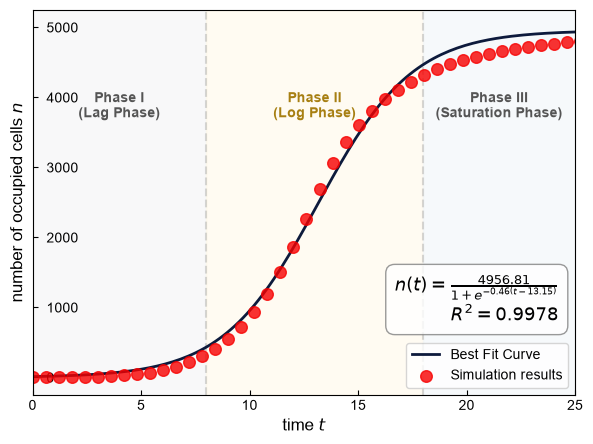

In [135]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

color2 = "#ECB00A"
color1 = "#0d1a3c"


# 1. Define the logistic model function
def logistic_model(t, N_0, k, t_0):
    return N_0 / (1 + np.exp(-k * (t - t_0)))


N = 150

# 2. Load data from the .dat file
data = np.loadtxt("original,average_n_vs_t,sims=500,k=0.60,H=0.02.dat")

# Extract columns
y_data = data[:, 0]  # number of occupied sites
t_data = data[:, 1]  # x-axis represents independent variable 't'

# Clean NaNs
mask = ~np.isnan(t_data) & ~np.isnan(y_data)
y_data = y_data[mask]
t_data = t_data[mask]

# Sort data by time (required for np.interp to work reliably)
sort_indices = np.argsort(t_data)
t_data = t_data[sort_indices]
y_data = y_data[sort_indices]

# Resample onto uniform time grid
t_uniform = np.linspace(t_data.min(), t_data.max(), N)
y_uniform = np.interp(t_uniform, t_data, y_data)

initial_guesses = [max(y_uniform), 1.0, np.median(t_uniform)]

# --- Perform the curve fit ---
popt, pcov = curve_fit(
    logistic_model, t_uniform, y_uniform, p0=initial_guesses
)

# Unpack fitted parameters
N_0_opt, k_opt, t_0_opt = popt

# 4. Calculate R^2 (Coefficient of Determination)
y_pred = logistic_model(t_uniform, *popt)
ss_res = np.sum((y_uniform - y_pred) ** 2)
ss_tot = np.sum((y_uniform - np.mean(y_uniform)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

# 5. Generate smooth curves for plotting
t_fit = np.linspace(min(t_data), max(t_data), 500)
y_fit = logistic_model(t_fit, *popt)

# 6. Formatting & Font Configuration
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = (
    "dejavusans"  # Clean fallback math font if needed
)

# Create the figure
fig, ax = plt.subplots(figsize=(7, 5))

phase1_end = 8
phase2_end = 18
plot_xmax = 25
text_height_ratio = 0.75

# Add shaded background regions (zorder=0 to keep them behind data)
ax.axvspan(0, phase1_end, color="#f4f4f6", alpha=0.6, zorder=0)  # Light grey
ax.axvspan(
    phase1_end, phase2_end, color="#fff9e6", alpha=0.5, zorder=0
)  # Soft yellow
ax.axvspan(
    phase2_end, plot_xmax, color="#f1f6f9", alpha=0.6, zorder=0
)  # Soft blue/grey

# Add text labels tracking data coordinates horizontally and axes fractions vertically
ax.text(
    (0 + phase1_end) / 2,
    text_height_ratio,
    "Phase I\n(Lag Phase)",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#555555",
    zorder=3,
)
ax.text(
    (phase1_end + phase2_end) / 2,
    text_height_ratio,
    "Phase II\n(Log Phase)",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#A77F12",
    zorder=3,
)
ax.text(
    (phase2_end + plot_xmax) / 2,
    text_height_ratio,
    "Phase III\n(Saturation Phase)",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#555555",
    zorder=3,
)

# Subtle vertical dashed lines at boundaries
ax.axvline(phase1_end, color="gray", linestyle="--", alpha=0.3, zorder=1)
ax.axvline(phase2_end, color="gray", linestyle="--", alpha=0.3, zorder=1)

# Plot the raw uniform data and fitted curve
ax.plot(t_fit, y_fit, color=color1, linewidth=2, label="Best Fit Curve", zorder=1)
ax.scatter(
    t_uniform,
    y_uniform,
    s=70,
    marker="o",
    color="#F70000",
    alpha=0.8,
    label="Simulation results",
    zorder=2,
)

# 7. Display fitted equation on plot
equation_text = (
    f"$n(t) = \\frac{{{N_0_opt:.2f}}}{{1 + e^{{-{k_opt:.2f}(t - {t_0_opt:.2f})}}}}$\n"
    f"$R^2 = {r_squared:.4f}$"
)

ax.text(
    0.97,
    0.18,  # x near right edge, y elevated safely above the legend box
    equation_text,
    transform=ax.transAxes,
    fontsize=13,
    horizontalalignment="right",  # Right-align the text box boundaries
    verticalalignment="bottom",  # Push text upwards from its coordinate floor
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", alpha=0.8
    ),
    zorder=5,
)

# 8. Adjust ticks and labels to point and align INSIDE
ax.tick_params(axis="both", which="both", direction="in")
ax.tick_params(
    axis="y", pad=-10
)  # Pulls the tick scale numbers inside the plot area

# Format alignment for the Y-axis tick labels so they read neatly inside
for label in ax.get_yticklabels():
    label.set_horizontalalignment("left")

# Axis titles
ax.set_xlabel(r"time $\mathit{t}$", fontsize=12)
ax.set_ylabel(r"number of occupied cells $\mathit{n}$", fontsize=12)

# --- FIXED LEGEND CALL ---
ax.legend(
    loc="lower right"
)

ax.set_xlim(0, plot_xmax)

plt.savefig(
    "logistic_growth_phases.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight",
)

plt.show()


# n(t) vs k
superposition of different values of n(t) vs k. k = 0, 0.2, 0.4, 0.6, 0.8

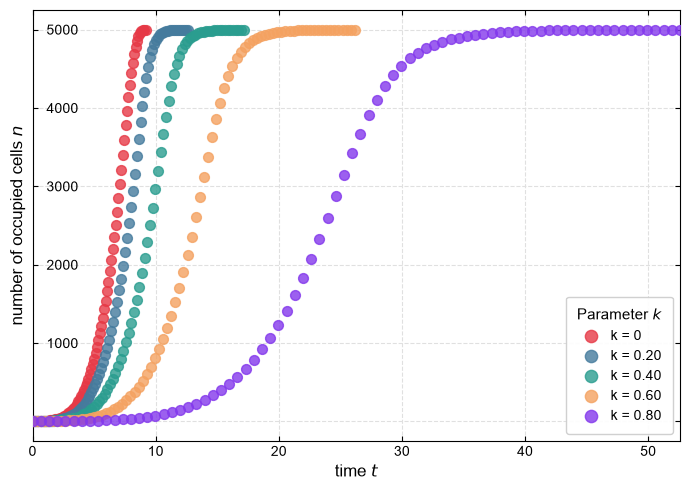

In [30]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
import re  # 1. Import regular expressions

N = 80 

# Define the 5 files you want to compare
file_list = [
    "enclosed_average_n_vs_t,sims=500,k=0,H=0.02.dat",
    "enclosed_average_n_vs_t,sims=500,k=0.20,H=0.02.dat",
    "enclosed_average_n_vs_t,sims=500,k=0.40,H=0.02.dat",
    "enclosed_average_n_vs_t,sims=500,k=0.60,H=0.02.dat",
    "enclosed_average_n_vs_t,sims=500,k=0.80,H=0.02.dat"
]

colors = ["#E63946", "#457B9D", "#2A9D8F", "#F4A261", "#8338EC"]
markers = ["o", "s", "^", "D", "v"]

fig, ax = plt.subplots(figsize=(7, 5))

# Loop over each file to extract, fit, and plot data
for i, filename in enumerate(file_list):
    try:
        data = np.loadtxt(filename)
        y_data = data[:, 0]
        t_data = data[:, 1]

       # Clean NaNs
        mask = ~np.isnan(t_data) & ~np.isnan(y_data)
        y_data = y_data[mask]
        t_data = t_data[mask]

        # Sort data by time (required for np.interp to work reliably)
        sort_indices = np.argsort(t_data)
        t_data = t_data[sort_indices]
        y_data = y_data[sort_indices]

        # Resample onto uniform time grid
        t_uniform = np.linspace(t_data.min(), t_data.max(), N)
        y_uniform = np.interp(t_uniform, t_data, y_data)
        
        # --- NEW: Extract the 'k' value from the filename ---
        # This matches "k=" followed by an integer or decimal number
        match = re.search(r"k=([0-9.]+)", filename)
        k_value = match.group(1) if match else "Unknown"
        
        # Plot cleaned, spaced-out scatter points with the new 'k' label
        ax.scatter(
            t_uniform, y_uniform, 
            color=colors[i], marker="o", alpha=0.8, s=50, zorder=3,
            label=f"k = {k_value}"  # Updated label
        )
    
        
    except Exception as e:
        print(f"Could not process file '{filename}': {e}")

# --- AXIS & TICK STYLING ---
ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
ax.tick_params(axis="y", pad=-10)

for label in ax.get_yticklabels():
    label.set_horizontalalignment("left")

ax.set_xlabel(r"time $\mathit{t}$", fontsize=12)
ax.set_ylabel(r"number of occupied cells $\mathit{n}$", fontsize=12)

if max_t > 0:
    ax.set_xlim(0, max_t)

# --- ENHANCED GRID ---
ax.set_axisbelow(True)  # Grid stays behind scatter points
ax.grid(True, which="major", color="#E0E0E0", linestyle="--", linewidth=0.8)

# --- ENHANCED LEGEND ---
ax.legend(
    title=r"Parameter $\mathit{k}$",
    title_fontsize=11,
    fontsize=10,
    loc="lower right",
    frameon=True,
    facecolor="#FFFFFF",
    edgecolor="#CCCCCC",
    framealpha=0.92,
    fancybox=True,
    borderpad=0.8,
    labelspacing=0.5,
    handletextpad=0.4,
    markerscale=1.25,
)

plt.tight_layout()
plt.savefig(
    "vary_k.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight",
)


plt.show()

# the 3 parameter fitting 

Fitted D: 21.6676
Fitted beta: 23.5456
Fitted gamma: 0.5183
R^2 score: 0.9995


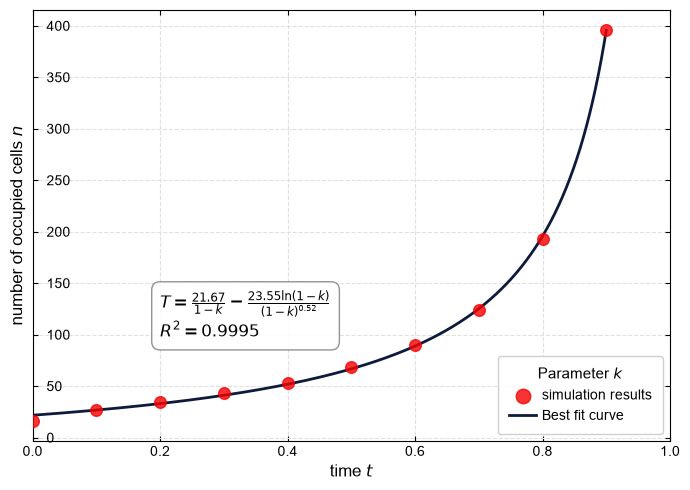

In [44]:
from math import log
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

data1 = np.loadtxt("cpath_orig,sims=500,k=0.0,H=0.02.dat")
k1 = data1[:, 0]
t1 = data1[:, 1]


# 1. Define the 3-parameter Logistic Growth Model
def occupation_time(k, D, beta, gamma):
    return D / (1 - k) - beta * np.log(1 - k) / ((1 - k) ** gamma)


# Fit curve
p0 = [10, 33, 1.0]
popt, _ = curve_fit(occupation_time, k1, t1, p0=p0)
D_fit, beta_fit, gamma_fit = popt


# --- Calculate Coefficient of Determination (R^2) ---
t1_pred = occupation_time(k1, *popt)
ss_res = np.sum((t1 - t1_pred) ** 2)
ss_tot = np.sum((t1 - np.mean(t1)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print(f"Fitted D: {D_fit:.4f}")
print(f"Fitted beta: {beta_fit:.4f}")
print(f"Fitted gamma: {gamma_fit:.4f}")
print(f"R^2 score: {r2:.4f}")

# Plotting
k_dense = np.linspace(min(k1), max(k1), 1000)
t_fit = occupation_time(k_dense, D_fit, beta_fit, gamma_fit)

# Handle signs cleanly
sign = "-" if beta_fit >= 0 else "+"
abs_beta = abs(beta_fit)

# Formatted equation with closing math delimiter ($)
eq_str = (
    rf"$T = \frac{{{D_fit:.2f}}}{{1 - k}} {sign} \frac{{{abs_beta:.2f} \ln(1 - k)}}{{(1 - k)^{{{gamma_fit:.2f}}}}}$"
    f"\n$R^2 = {r2:.4f}$"
)

# Create the figure
fig, ax = plt.subplots(figsize=(7, 5))

# Plot data & fit line
ax.scatter(
            k1, t1, 
            color="#F70000", marker="o", alpha=0.8, s=70, zorder=3, label = 'simulation results'  # Updated label
        )
ax.plot(k_dense, t_fit, label="Best fit curve", color="#0d1a3c", linewidth=2, zorder=2)

# Dedicated text box for equation in open space (upper-left)
ax.text(
    0.20,
    0.35,
    eq_str,
    transform=ax.transAxes,
    fontsize=12,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="white", alpha=0.85, edgecolor="gray"
    ),
)


# --- AXIS & TICK STYLING ---
ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
ax.tick_params(axis="y", pad=-10)

for label in ax.get_yticklabels():
    label.set_horizontalalignment("left")

ax.set_xlabel(r"time $\mathit{t}$", fontsize=12)
ax.set_ylabel(r"number of occupied cells $\mathit{n}$", fontsize=12)

if max_t > 0:
    ax.set_xlim(0, 1)

# --- ENHANCED GRID ---
ax.set_axisbelow(True)  # Grid stays behind scatter points
ax.grid(True, which="major", color="#E0E0E0", linestyle="--", linewidth=0.8)

# --- ENHANCED LEGEND ---
ax.legend(
    title=r"Parameter $\mathit{k}$",
    title_fontsize=11,
    fontsize=10,
    loc="lower right",
    frameon=True,
    facecolor="#FFFFFF",
    edgecolor="#CCCCCC",
    framealpha=0.92,
    fancybox=True,
    borderpad=0.8,
    labelspacing=0.5,
    handletextpad=0.4,
    markerscale=1.25,
)

plt.tight_layout()
plt.savefig(
    "3 parameter fitting.png",
    dpi=300,
    transparent=True,
    bbox_inches="tight",
)


plt.show()
